# Airline Operations & Delay Analytics
### From official BTS records to defensible operational decisions

**Advanced data analytics capstone · Python notebook · 10 reproducible phases**

This notebook follows the supplied airline assignment. It uses official BTS monthly delay-cause records for **2018–2025**. Its scope is operational delay analysis; there are no passenger satisfaction records, route origins, or individual aircraft identifiers. No unsupported fields are invented.

**Research question:** How do delay exposure and operational patterns vary across airports, carriers, and months, and can historical information anticipate future monthly delay rates?

**Learning route:** business understanding → acquisition → audit/cleaning → KPI design → EDA → hypothesis testing → prediction → forecasting → decisions → reproducibility.

If the course currently requires only material through hypothesis testing, present **Phases 1–6** as the core submission. Phases 7–10 provide the complete capstone extension. This project was prepared with AI assistance; understand, rerun and attribute it according to course rules.

## Setup

Install `requirements.txt` in a virtual environment as described in the README. Start Jupyter in the project root or notebook directory. The code below finds the project and imports reusable functions; `src/analysis.py` contains every transformation. Bundled raw files allow offline analysis after dependencies are installed. Full execution may take a few minutes.

In [1]:
from pathlib import Path
import sys, json, inspect
import pandas as pd
import numpy as np
from IPython.display import display, Markdown, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/analysis.py').exists() and (p / 'data/raw/provenance.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Open Jupyter from the project root or notebooks folder.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.analysis import (verify_source, audit_and_clean, kpi_tables, aggregate, charts,
                         seasonal_test, build_features, prediction_analysis, forecasting, sql_analysis)
from src.reporting import write_reports
pd.set_option('display.max_columns', 30)
print('Project:', ROOT.name)

Project: airline-delay-analytics


## Phase 1 — Business understanding

**Stakeholders:** airline operations managers, airport coordinators, and analysts. **Decision:** prioritize operational investigation and seasonal review capacity. Success means reliable definitions, reproducible results, and later-period error lower than a simple baseline where the data support it.

We cannot estimate staffing requirements, intervention effects, passenger satisfaction, or financial return because these variables are absent. Carrier rankings are not causal performance ratings: network mix, weather and airport conditions differ.

In [2]:
display(Markdown((ROOT / 'docs/BUSINESS_UNDERSTANDING.md').read_text()))

# Business understanding

## Decision and stakeholders

Airline operations managers, airport coordinators, and analysts need to identify concentrations of arrival disruption and plan review capacity. The project measures historical delay and cancellation exposure, examines a seasonal comparison, and evaluates whether historical monthly information can help anticipate future delay rates.

The primary decision is which carrier-airport segments merit operational investigation, with volume and uncertainty considered together. This analysis cannot prescribe staffing levels, individual flight interventions, or financial returns because capacity, costs, schedules, and intervention outcomes are absent.

## Scope

Official BTS monthly airline delay-cause data, all reporting carriers and airports returned for January 2018 through December 2025. Each row is a **year-month × carrier × arrival airport** summary. The chosen complete calendar years avoid a partial 2026 comparison. The download is a dated snapshot, not an immutable BTS release. No other dataset is substituted or joined.

The available data describe aggregate operations. They contain no passenger satisfaction labels, route origins, individual aircraft identifiers, passenger characteristics, or individual flight timestamps. Accordingly, satisfaction prediction, route comparisons, aircraft-level explanations, and passenger fairness analysis are out of scope. Carrier and airport codes are entity identifiers, not personal identifiers.

## Success criteria

1. Reconcile counts, identify missingness and invalid records, and define denominators precisely.
2. Produce at least six reproducible visualizations and one justified statistical comparison.
3. Evaluate a historical-information prediction model against a lag baseline on a later year, reporting honestly if it fails to improve.
4. Evaluate national monthly delay-rate forecasts against seasonal naive forecasts on a held-out later year.
5. Turn findings into specific investigation priorities with monitoring measures and limitations.

## Prediction decision time

At the start of month t, predict the **monthly carrier-airport late-arrival share**, not an individual flight's outcome. Use calendar month, carrier, airport, and outcomes from t-3 and t-12 only. BTS indicates monthly data are generally released about 30 days after month end; the three-month gap is deliberately conservative. Historical publication timestamps and revisions are unavailable, so the exercise is a retrospective as-of approximation. Production use would need actual release-vintage data.

## Recommended operating process

Review high-volume, high-delay segments monthly. Investigate causes with local managers before assigning resources; use a limited pilot and compare outcomes over comparable months. Monitor late-arrival share, cancellation share, flight volume, prediction error, and missing-data alerts. Avoid treating a carrier ranking as a causal measure of carrier quality: airport mix, weather, season, and schedules differ.


## Phase 2 — Acquisition, provenance and grain

The assignment specifies [BTS TranStats](https://www.transtats.bts.gov/). We selected its official **Airline On-Time Statistics and Delay Causes** raw download, requesting all carriers and airports for January 2018–December 2025. These complete years avoid partial-year 2026 comparisons. The source summarizes operations at **year-month × carrier × arrival airport**, not individual flight grain.

The ZIP contains an unchanged CSV and an original column-definition workbook. The CSV has 21 columns; the actual audit verifies its size and schema. Exact server filename, URL, date, byte sizes and SHA-256 hashes are recorded. BTS did not provide an immutable version identifier; the hashes identify this snapshot. No external join is needed.

In [3]:
provenance = verify_source()
display(pd.Series({k: v for k, v in provenance.items() if k != 'files'}).to_frame('value'))
display(pd.DataFrame(provenance['files']).T)
raw = pd.read_csv(ROOT / 'data/raw/Airline_Delay_Cause.csv')
print('Actual raw shape:', raw.shape)
display(raw.head())
display(raw.dtypes.to_frame('dtype'))

,value
publisher,US DOT Bureau of Transportation Statistics
source_page,https://www.transtats.bts.gov/OT_Delay/OT_Dela...
download_url,https://www.transtats.bts.gov/OT_Delay/ot_dela...
download_date,2026-11-03
requested_period,2018-01 through 2025-12
carrier_selection,All
airport_selection,All
http_content_disposition,: attachment; filename=Airline_Delay_Cause_202...
archive_members,"[Airline_Delay_Cause.csv, Download_Column_Defi..."
release_version,No immutable release ID supplied by download e...


,bytes,sha256
bts_delay_causes_2018_2025.zip,7064858,94df580beb6394d6cdb45815b8d5f47aef4273a2c27639...
Airline_Delay_Cause.csv,31211051,f88bd9719c484304a8125eae5a7a690ef5f07a1a52ee6e...


Actual raw shape: (186371, 21)


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,nas_ct,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2025,12,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",90.0,29.0,15.33,0.09,5.65,0.0,7.93,3.0,0.0,2003.0,1024.0,12.0,192.0,0.0,775.0
1,2025,12,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",44.0,14.0,5.89,1.80,0.19,0.0,6.12,0.0,0.0,1223.0,491.0,136.0,13.0,0.0,583.0
2,2025,12,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",81.0,26.0,7.35,0.73,3.09,0.0,14.83,0.0,0.0,2162.0,588.0,33.0,205.0,0.0,1336.0
3,2025,12,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",76.0,15.0,10.14,0.10,1.66,0.0,3.10,1.0,1.0,1695.0,975.0,20.0,272.0,0.0,428.0
4,2025,12,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",56.0,24.0,5.17,1.00,4.39,0.0,13.44,4.0,0.0,2871.0,1397.0,21.0,212.0,0.0,1241.0


,dtype
year,int64
month,int64
carrier,str
carrier_name,str
airport,str
airport_name,str
arr_flights,float64
arr_del15,float64
carrier_ct,float64
weather_ct,float64


## Phase 3 — Audit, cleaning and validation

Audit missingness, exact and business-key duplicates, dates, categories, numeric limits, logical count relationships, outliers, identifiers and leakage. Preserve the source and write a separate cleaned table.

Treatment rules are explicit:

1. Trim surrounding whitespace, retaining source name changes and grouping by entity codes.
2. Derive a missing delayed-arrival count as **zero only if every flight was cancelled/diverted and every delay/cause counter is explicitly zero**.
3. Exclude rows still missing required outcomes or volume; do not pretend their unknown volume is zero.
4. Retain extreme observations and pandemic months; report IQR flags rather than deleting legitimate disruptions.
5. Preserve discrepancies between total and cause-attributed minutes as an unallocated gap.
6. Never fill absent carrier-airport-month combinations with zero flights.

In [4]:
df, audit = audit_and_clean()
display(pd.Series({k: v for k, v in audit.items()
                   if not isinstance(v, dict)}).to_frame('audit result'))
display(pd.Series(audit['missing_by_field']).to_frame('raw missing rows'))
display(pd.read_csv(ROOT / 'reports/outlier_profile.csv'))
display(pd.read_csv(ROOT / 'reports/missingness_segments.csv').query('missing_outcomes > 0').head(12))
print('Source remains unchanged:', verify_source()['requested_period'])

,audit result
raw_rows,186371
raw_columns,21
exact_duplicates,0
business_key_duplicates,0
invalid_date_rows,0
invalid_airport_codes,0
structural_zero_delayed_count_rows,250
excluded_rows_missing_or_nonpositive_volume,322
excluded_known_flight_volume,0.0
rows_cause_minutes_not_reconciled,20


,raw missing rows
year,0
month,0
carrier,0
carrier_name,0
airport,0
airport_name,0
arr_flights,322
arr_del15,572
carrier_ct,322
weather_ct,322


,field,iqr_low,iqr_high,flagged_rows,treatment
0,arr_flights,-209.0,447.0,23683,Retained
1,arr_del15,-44.5,87.5,23662,Retained
2,arr_cancelled,-4.5,7.5,25068,Retained
3,arr_diverted,0.0,0.0,45590,Retained
4,arr_delay,-3120.0,5960.0,23088,Retained


,year,carrier,rows,missing_outcomes
0,2018,9E,1295,8
4,2018,AX,874,2
7,2018,CP,397,2
8,2018,DL,1758,1
10,2018,EV,1365,5
12,2018,G4,1406,1
13,2018,G7,907,3
16,2018,MQ,1582,2
18,2018,OH,1126,1
19,2018,OO,2759,4


Source remains unchanged: 2018-01 through 2025-12


Missingness is systematic enough to inspect by year and carrier, not merely total count. A globally complete 96-month timeline does not imply a complete carrier-airport panel. Legitimate carrier and airport names may change while their grouping code remains stable. The detailed audit includes column cardinalities, negative checks, date coverage and source reconciliation gaps.

The selected schema contains no passenger names, contact details, free text or direct personal identifiers. Carrier/airport codes identify public entities. Same-month outcome fields are leakage risks for prediction, even though they are appropriate for descriptive charts.

In [5]:
display(Markdown((ROOT / 'docs/DATA_DICTIONARY.md').read_text()))
display(pd.read_csv(ROOT / 'reports/numeric_profile.csv').round(2))

# Data dictionary, provenance and availability

Publisher: US Department of Transportation, Bureau of Transportation Statistics (BTS). Dataset: *Airline On-Time Statistics and Delay Causes*. Official page: https://www.transtats.bts.gov/OT_Delay/OT_DelayCause1.asp. Retrieved 3 November 2026 for January 2018–December 2025, all carriers and airports returned by the source.

Original CSV: `Airline_Delay_Cause.csv`. The unchanged original download archive is preserved as `bts_delay_causes_2018_2025.zip`; its exact server-provided filename, contained filenames, bytes, URL, date and SHA-256 hashes are in `raw/provenance.json`. The server's filename timestamp may use a different timezone from the local retrieval date. No immutable release/version ID was supplied. The ZIP also preserves BTS's original column-definition workbook. The CSV has 186,371 rows and 21 columns before cleaning.

Grain: **year-month × carrier × arrival airport**. No external joins are used. Internally, derived historical feature tables join on carrier, airport and exact shifted calendar month, with one-to-one validation.

| Original field | Type loaded | Meaning / unit | Available before target month? |
|---|---|---|---|
| year | Integer | Calendar year | Yes |
| month | Integer | Calendar month, 1–12 | Yes |
| carrier | String | Reporting carrier code | Entity identity; not directly modelled |
| carrier_name | String | Source carrier label; may change over time | Label; not modelled |
| airport | String | Arrival airport code | Entity identity; not directly modelled |
| airport_name | String | Airport label; may change over time | Label; not modelled |
| arr_flights | Float | Reported arriving/scheduled flight count in source scope | No, realized monthly count |
| arr_del15 | Float | Count of arrivals delayed at least 15 minutes | No, target numerator |
| carrier_ct | Float | Fractional delayed-flight attribution to air carrier | No |
| weather_ct | Float | Fractional delayed-flight attribution to extreme weather | No |
| nas_ct | Float | Fractional delayed-flight attribution to NAS | No |
| security_ct | Float | Fractional delayed-flight attribution to security | No |
| late_aircraft_ct | Float | Fractional delayed-flight attribution to late aircraft | No |
| arr_cancelled | Float | Cancellation count | No |
| arr_diverted | Float | Diversion count | No |
| arr_delay | Float | Total delay minutes for delayed arrivals | No |
| carrier_delay | Float | Air-carrier-attributed delay minutes | No |
| weather_delay | Float | Extreme-weather-attributed delay minutes | No |
| nas_delay | Float | NAS-attributed delay minutes | No |
| security_delay | Float | Security-attributed delay minutes | No |
| late_aircraft_delay | Float | Late-aircraft-attributed delay minutes | No |

Counts are kept as floating point to preserve source values and missingness. Fractional cause counts reflect prorated attribution, not fractional physical aircraft. Monthly volume is not a pre-decision feature. Current-month outcomes are used for descriptive analysis and evaluation only.

## Derived fields

| Field | Definition |
|---|---|
| date | First day of observation month; represents a monthly period, not a flight date |
| on_time | arr_flights − arr_del15 − arr_cancelled − arr_diverted |
| delay_rate | arr_del15 / arr_flights, fraction 0–1 |
| cancel_rate | arr_cancelled / arr_flights, fraction 0–1 |
| delay_burden | arr_delay / arr_flights, minutes per reported flight |
| cause_minutes_gap | arr_delay − sum of five cause-minute columns |
| month_sin, month_cos | Circular calendar-month encoding with period 12 |
| log_volume | log(1 + arr_flights), used only to construct historical volume |
| lag3_delay_rate, lag12_delay_rate | Same carrier-airport rate exactly 3 or 12 months earlier |
| lag3_cancel_rate | Cancellation share exactly 3 months earlier |
| lag3_delay_burden | Delay minutes per reported flight exactly 3 months earlier |
| lag3_log_volume | log(1 + flight volume) exactly 3 months earlier |

No satisfaction labels, passenger information, route origins, departure schedules, aircraft IDs, weather measurements or ticket revenues are present. Do not manufacture them or combine unrelated datasets to imply they were observed.

## Source conditions

The source makes its statistical raw data publicly downloadable. The download contains no dataset-specific license identifier or separate license text; this project does not invent one or apply the code license to the data. Preserve BTS attribution and source links, review applicable source terms for subsequent reuse, and do not imply BTS endorses this analysis. Original public statistical facts and project code have distinct provenance. No personal records or credentials are included.

Definitions: https://www.bts.gov/explore-topics-and-geography/topics/airline-time-performance-and-causes-flight-delays. BTS includes some non-extreme weather in NAS attribution; the weather field is not total weather impact. Source scope includes the reporting arrangements described on the official page from January 2018 onward. These aggregates cannot independently verify flight-level deduplication.


,Unnamed: 0,count,mean,std,min,25%,50%,75%,max
0,year,186371.0,2021.42,2.31,2018.0,2019.00,2021.00,2023.00,2025.00
1,month,186371.0,6.49,3.46,1.0,3.00,6.00,10.00,12.00
2,arr_flights,186049.0,305.57,889.98,1.0,37.00,85.00,201.00,21931.00
3,arr_del15,185799.0,57.34,169.11,0.0,5.00,14.00,38.00,5544.00
4,carrier_ct,186049.0,18.43,49.49,0.0,1.89,5.16,14.03,1886.58
5,weather_ct,186049.0,2.13,7.76,0.0,0.00,0.27,1.71,343.38
6,nas_ct,186049.0,16.21,56.04,0.0,1.00,3.19,9.31,1884.42
7,security_ct,186049.0,0.15,0.72,0.0,0.00,0.00,0.00,58.69
8,late_aircraft_ct,186049.0,20.34,67.33,0.0,1.00,4.18,12.80,2588.13
9,arr_cancelled,186049.0,6.48,40.57,0.0,0.00,1.00,3.00,4951.00


## Phase 4 — Feature engineering and KPIs

Derived on-time count = reported flights − late arrivals − cancellations − diversions. Late means arrival at least 15 minutes behind schedule under BTS definitions. Each rate divides **summed numerators by summed denominators**; averaging row percentages would over-weight tiny operations.

For example, one delayed flight among 1 flight and one among 99 flights produce 2/100 = 2%, not an unweighted average of 100% and about 1%. Delay minutes per delayed arrival is different from delay burden per reported flight. A zero denominator produces missing, not a zero rate.

In [6]:
tables, metrics = kpi_tables(df)
display(pd.Series(metrics).to_frame('2018–2025 reporting scope'))
display(Markdown((ROOT / 'docs/KPI_DEFINITIONS.md').read_text()))
display(tables['annual'].round(2))

,2018–2025 reporting scope
reported_flights,5.685063e+07
late_arrival_pct,1.873917e+01
cancellation_pct,2.119952e+00
diversion_pct,2.429331e-01
minutes_per_delayed_arrival,6.930869e+01
unallocated_delay_minutes_pct,8.491692e-04


# KPI definitions

All rates use sums of counts, never an unweighted average of row percentages. The grain can be the full analysis period, month, carrier, or airport, and every output states its scope.

| KPI | Numerator | Denominator | Unit / interpretation |
|---|---|---|---|
| Reported flight volume | sum(arr_flights) | None | Flight records in selected BTS reporting scope |
| Late-arrival share | sum(arr_del15) | sum(arr_flights) | Percent; arrival delay at least 15 minutes |
| Cancellation share | sum(arr_cancelled) | sum(arr_flights) | Percent of reported flights |
| Diversion share | sum(arr_diverted) | sum(arr_flights) | Percent of reported flights |
| Derived on-time share | flights − delayed − cancelled − diverted | flights | Percent; mutually exclusive BTS outcome categories assumed and validated non-negative |
| Mean delay per delayed arrival | sum(arr_delay) | sum(arr_del15) | Minutes per late arrival; not mean delay across all flights |
| Delay burden per reported flight | sum(arr_delay) | sum(arr_flights) | Minutes per reported flight |
| Cause share of delay minutes | sum(selected *_delay) | sum(arr_delay) | Percent; source categories are operational attribution, not causal estimates |

Zero denominators produce missing rates, not zeros. `arr_del15` and cause-attributed flight counts can contain decimals because of source attribution/rounding; they are not forcibly cast to integers. Ranking tables apply a minimum of 10,000 reported flights over the chosen period; exploratory carrier-airport priority tables use the same threshold. This is a fixed display-stability rule, not a significance threshold.

Counts represent the downloaded reporting scope. The 2018 onward reporting structure includes reporting operating/marketing/codeshare arrangements described by BTS; these aggregates do not let us independently deduplicate individual flights. Results do not claim complete worldwide or all-US aviation coverage.


,arr_flights,arr_del15,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay,on_time,cause_minutes_gap,delay_pct,cancel_pct,divert_pct,on_time_pct,minutes_per_delayed
year,,,,,,,,,,,,,,,,,
2018,7848697.0,1481608.0,134493.0,19527.0,97188092.0,29014891.0,5334798.0,23518132.0,129886.0,39190385.0,6213069.0,0.0,18.88,1.71,0.25,79.16,65.60
2019,8091684.0,1527455.0,153629.0,20792.0,106446690.0,32309384.0,5719656.0,25344938.0,136524.0,42936188.0,6389808.0,0.0,18.88,1.90,0.26,78.97,69.69
2020,5022397.0,468955.0,301055.0,8411.0,29331196.0,12018903.0,2034653.0,6349900.0,64385.0,8862846.0,4243976.0,509.0,9.34,5.99,0.17,84.50,62.55
2021,6311871.0,1068059.0,111018.0,14982.0,71473480.0,28655723.0,4926309.0,12014666.0,227772.0,25648990.0,5117812.0,20.0,16.92,1.76,0.24,81.08,66.92
2022,7013508.0,1426305.0,190038.0,16663.0,96624825.0,38160150.0,5453002.0,16275923.0,197573.0,36537941.0,5380502.0,236.0,20.34,2.71,0.24,76.72,67.74
2023,7278739.0,1464539.0,93897.0,17797.0,102137829.0,36886747.0,5456183.0,18257737.0,211109.0,41325768.0,5702506.0,285.0,20.12,1.29,0.24,78.34,69.74
2024,7546968.0,1531080.0,102908.0,18831.0,110470639.0,37703237.0,6796376.0,20698537.0,182521.0,45088317.0,5894149.0,1651.0,20.29,1.36,0.25,78.10,72.15
2025,7736770.0,1685334.0,118168.0,21106.0,124695986.0,39693774.0,8044943.0,26910262.0,156523.0,49886915.0,5912162.0,3569.0,21.78,1.53,0.27,76.42,73.99


## Phase 5 — Exploratory and descriptive analysis

The following charts cover time trends, volume, carrier and airport differences, calendar segmentation, attributed causes and volume-risk trade-offs. Each states the population, denominator and period. Airport/carrier comparisons are descriptive and affected by mix. Reporting coverage is not all aviation.

Chart questions: Where are delay shares high? Does volume change the operational priority? Are disruption months seasonal? Which attributed minute categories dominate? Do rankings change when exposure is considered?

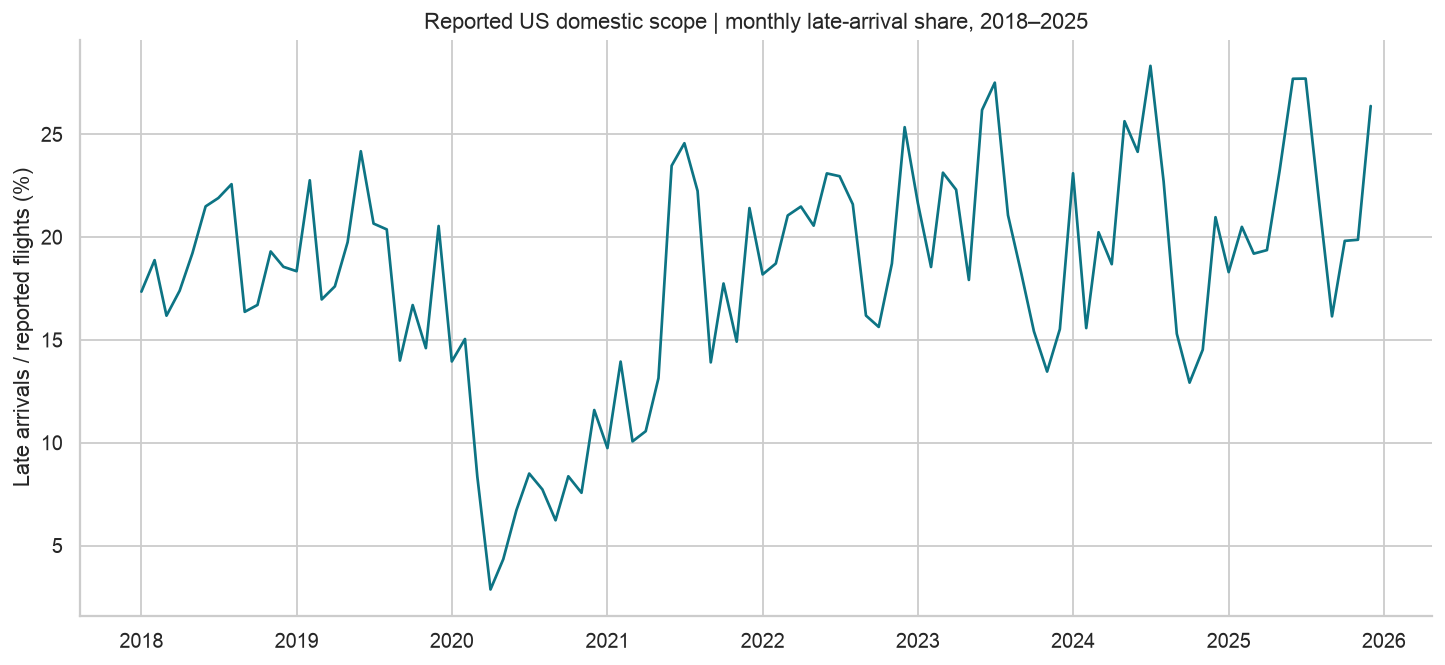

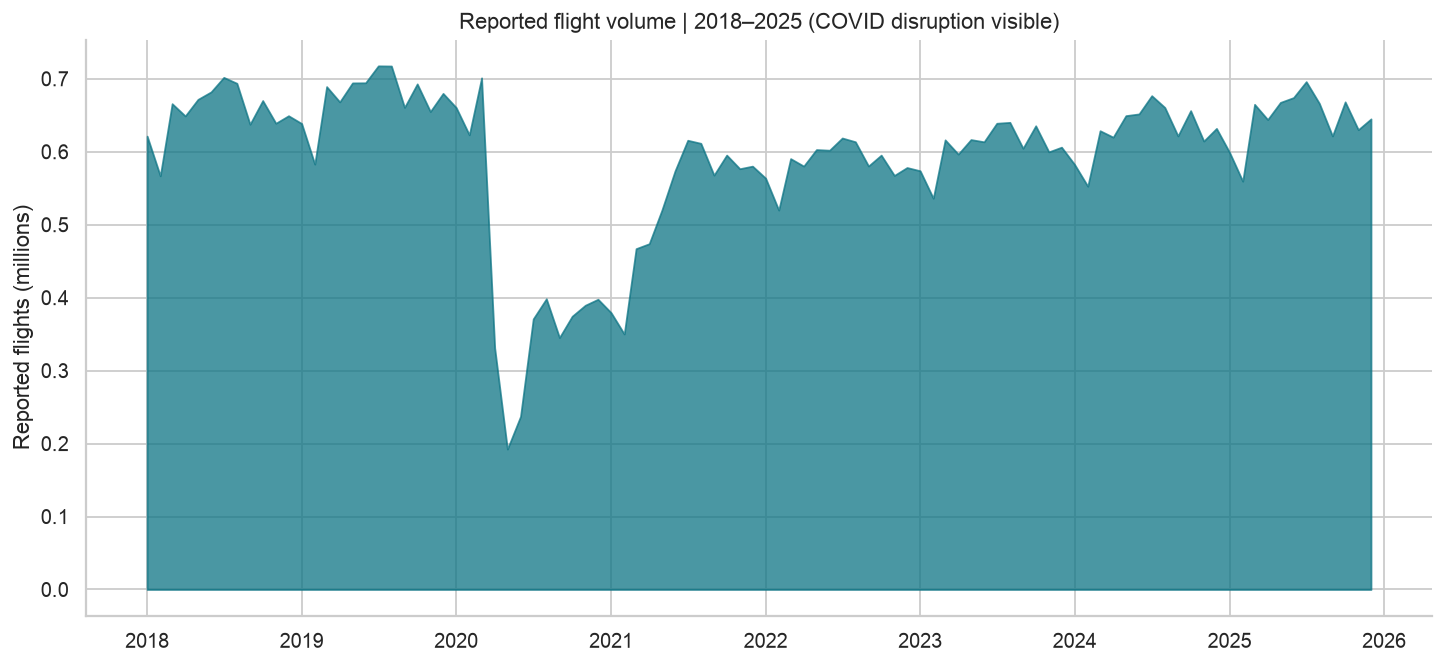

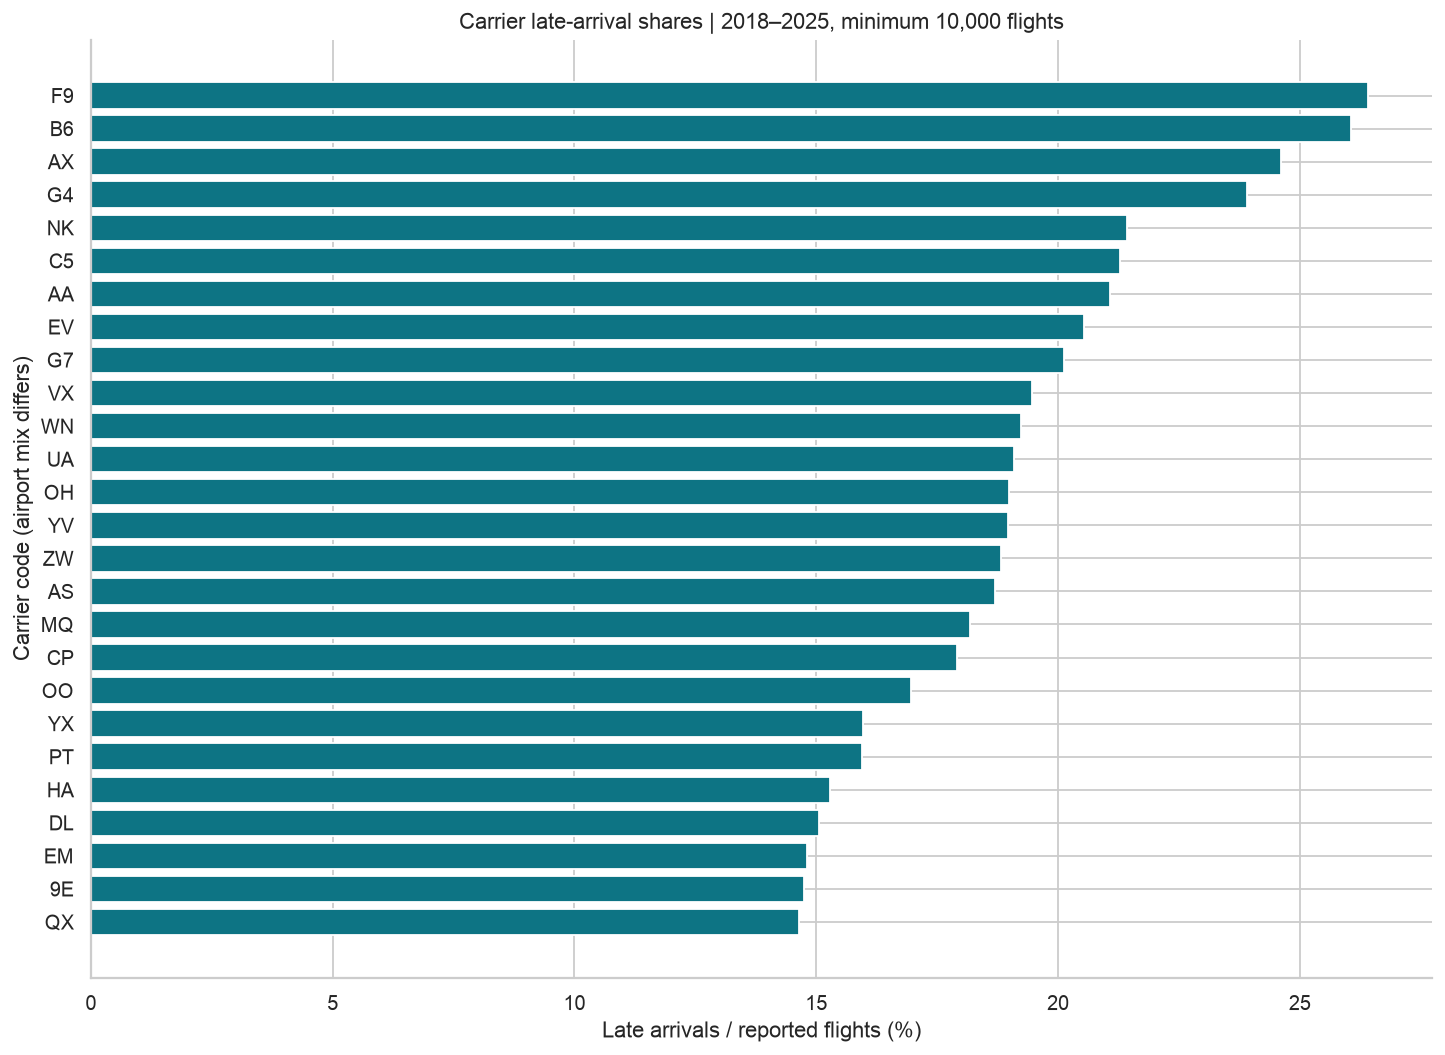

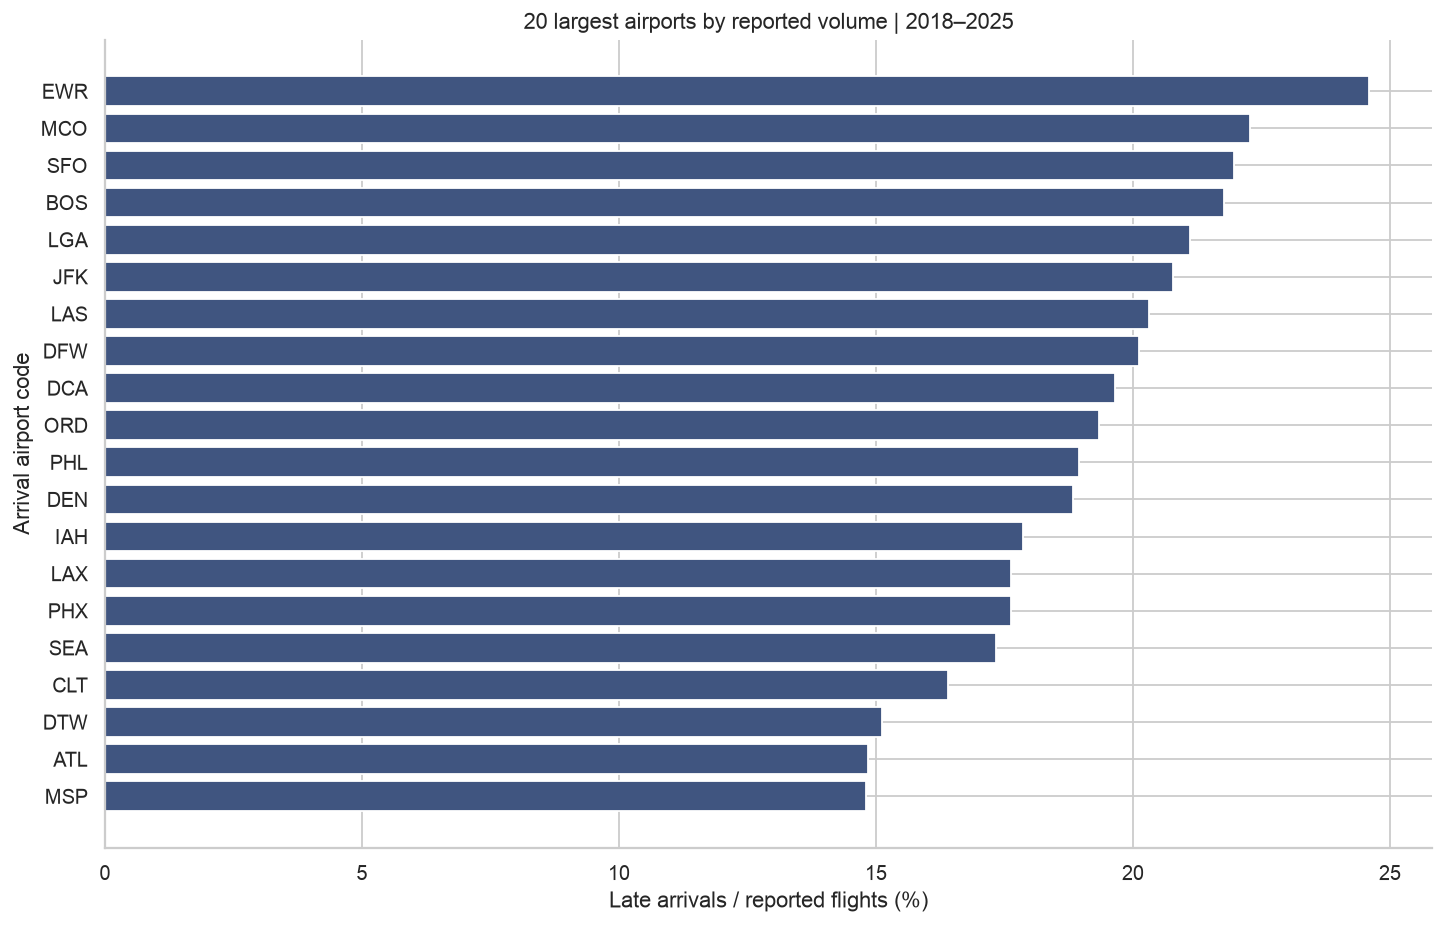

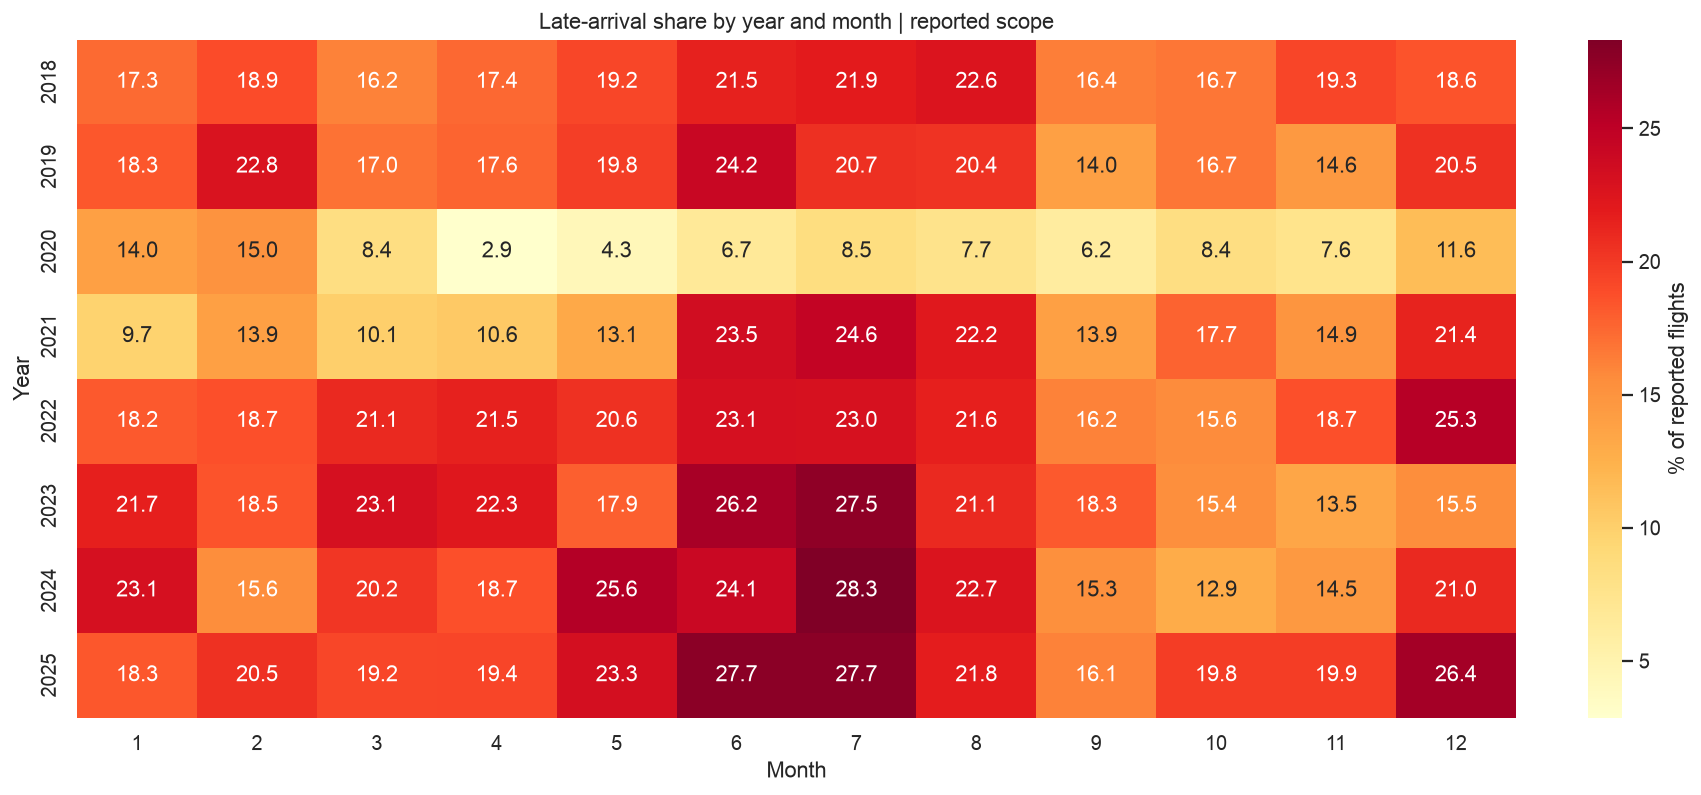

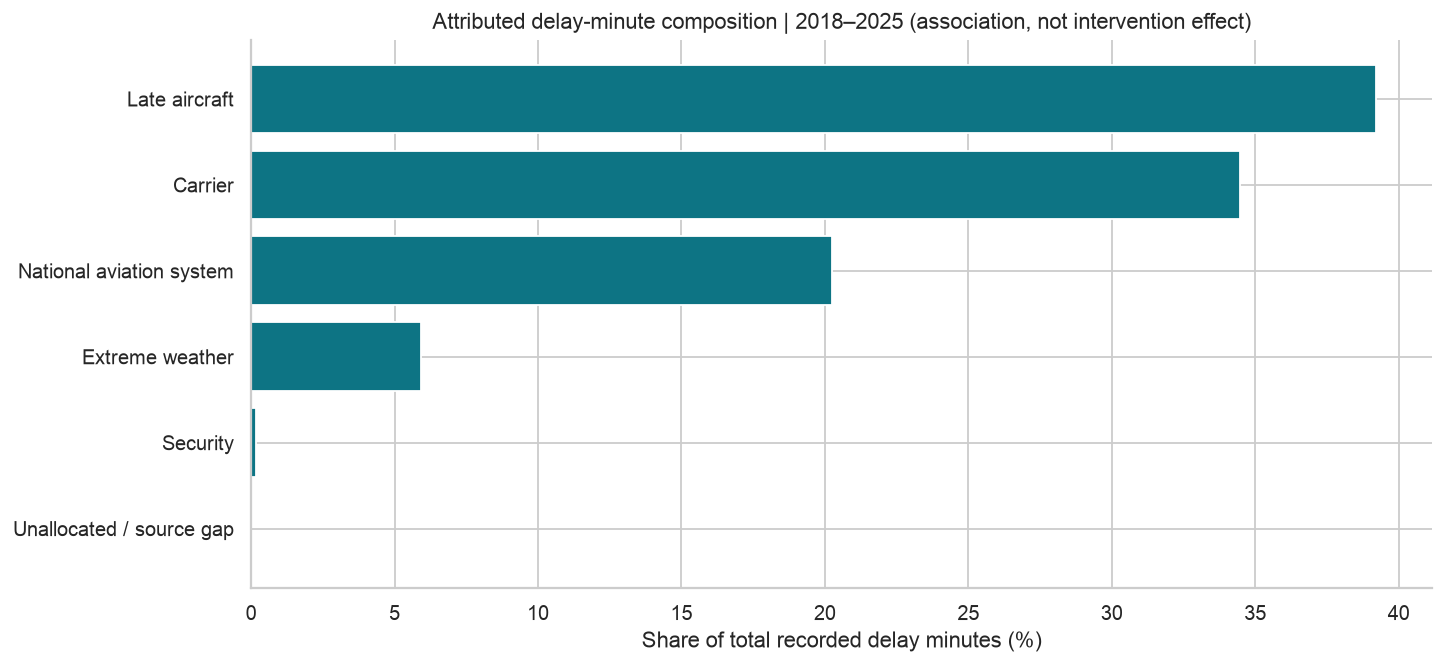

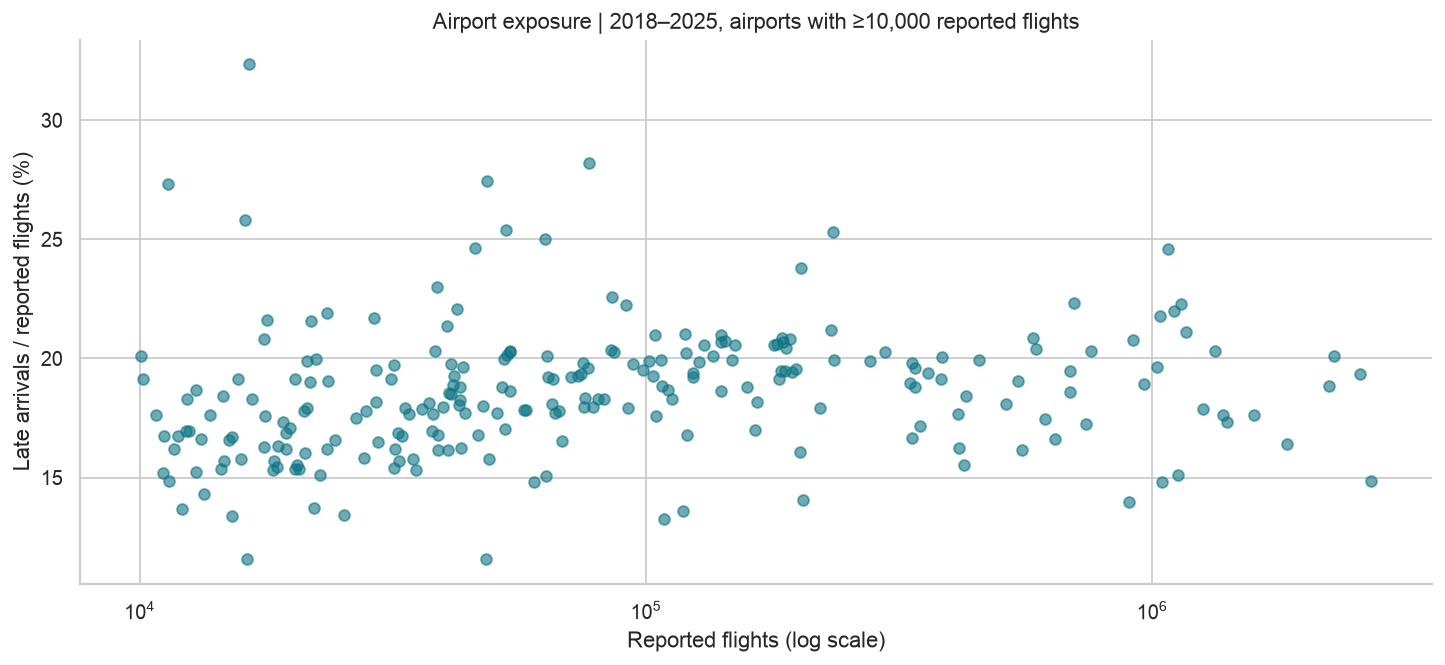

In [7]:
charts(df, tables)
for name in ['01_monthly_delay.png', '02_monthly_volume.png', '03_carrier_comparison.png',
             '04_airport_comparison.png', '05_seasonality_heatmap.png', '06_delay_causes.png',
             '10_volume_risk.png']:
    display(Image(filename=str(ROOT / 'reports/figures' / name)))

BTS cause counts are prorated when a delayed flight has several causes. The five cause groups are carrier, extreme weather, national aviation system (NAS), security and late aircraft. NAS can include non-extreme weather, so the extreme-weather field is not the complete weather impact. Cause attribution describes reporting categories; it is not an estimated avoidable benefit.

Use both high-volume hubs and high-rate segments when identifying review priorities. The 10,000-flight ranking threshold is a project display rule to reduce small-denominator volatility, not a statistical cutoff.

In [8]:
display(tables['carrier'].query('arr_flights >= 10000')
        .sort_values('delay_pct', ascending=False)[['arr_flights', 'delay_pct', 'cancel_pct']].round(2))
display(tables['airport'].nlargest(10, 'arr_flights')
        [['arr_flights', 'delay_pct', 'cancel_pct']].round(2))

,arr_flights,delay_pct,cancel_pct
carrier,,,
F9,1223605.0,26.42,2.27
B6,1968891.0,26.07,2.29
AX,178098.0,24.60,4.31
G4,896421.0,23.90,3.02
NK,1659375.0,21.43,2.01
C5,519188.0,21.27,3.01
AA,6942434.0,21.06,2.23
EV,389187.0,20.53,3.86
G7,495770.0,20.13,3.06


,arr_flights,delay_pct,cancel_pct
airport,,,
ATL,2701739.0,14.84,1.34
ORD,2569477.0,19.34,2.61
DFW,2290573.0,20.11,2.74
DEN,2235442.0,18.83,2.03
CLT,1850003.0,16.40,2.24
LAX,1587308.0,17.63,1.42
SEA,1405561.0,17.34,1.45
PHX,1377095.0,17.62,1.51
LAS,1332627.0,20.32,1.81


## Phase 6 — Hypothesis testing

**Decision question:** Is the typical major airport's summer late-arrival share meaningfully different from its autumn share?

Select the 30 largest airports using **2018–2022 volume**, then compare **June–August versus September–November during 2023–2025**. Within each airport-season, aggregate counts to a rate. Pair the two rates for the same airport; each airport receives equal weight. This avoids treating every monthly or individual flight observation as independent.

- H₀: mean airport summer-minus-autumn late-arrival share = 0.
- H₁: that mean difference is nonzero (two-sided).
- α = 0.05. Practical planning threshold = 2 percentage points, an explicit project assumption.
- Method: paired t-test on airport differences; report a 95% interval and paired Cohen dz.
- Check the difference distribution with a Q-Q plot and Shapiro diagnostic; examine a seeded sign-flip sensitivity result.

Assumptions: paired measurements, approximately independent airport differences, and a reasonably behaved mean-difference distribution. Airports share network/weather shocks, so independence is approximate. This purposive top-airport sample is not a random national sample. Conclusions are exploratory associations; the p-value does not measure the probability that H₀ is true.

,paired seasonal test
null,Mean airport summer-minus-autumn late-arrival ...
alternative,Two-sided mean difference != 0
alpha,0.05
analysis_years,2023–2025
selection,30 largest airports by reported 2018–2022 volume
paired_airports,30
mean_summer_pct,25.331239
mean_autumn_pct,16.400783
difference_pp,8.930456
ci_low_pp,7.99955


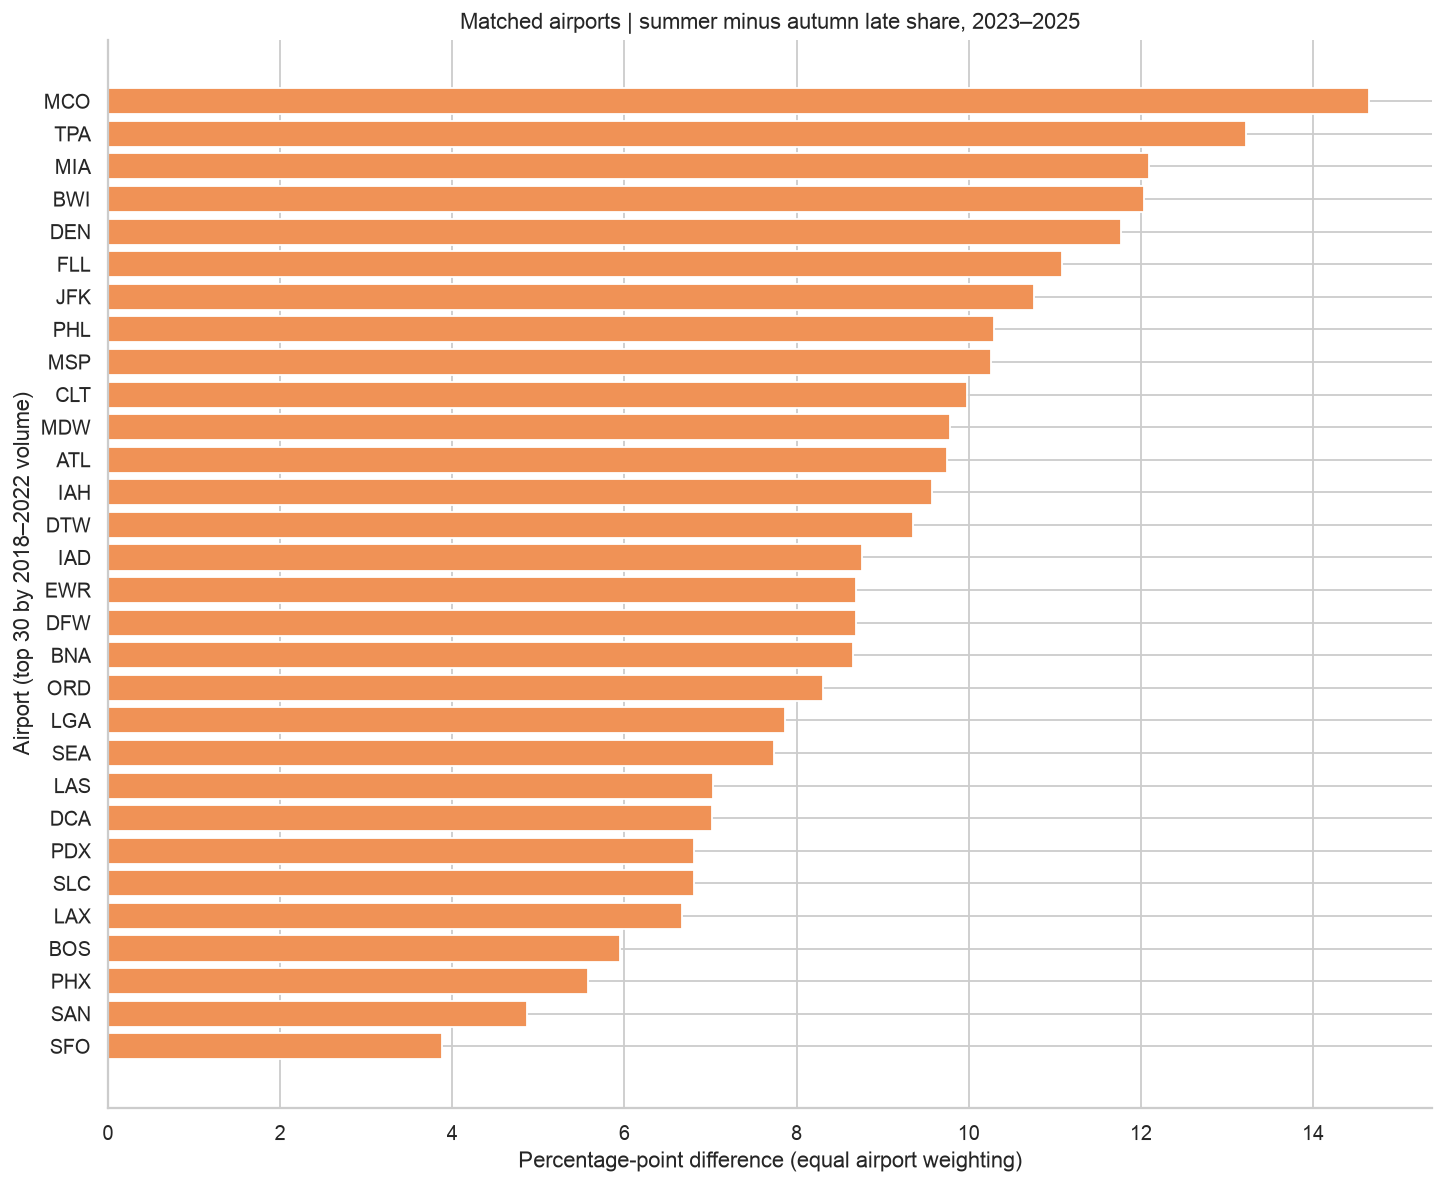

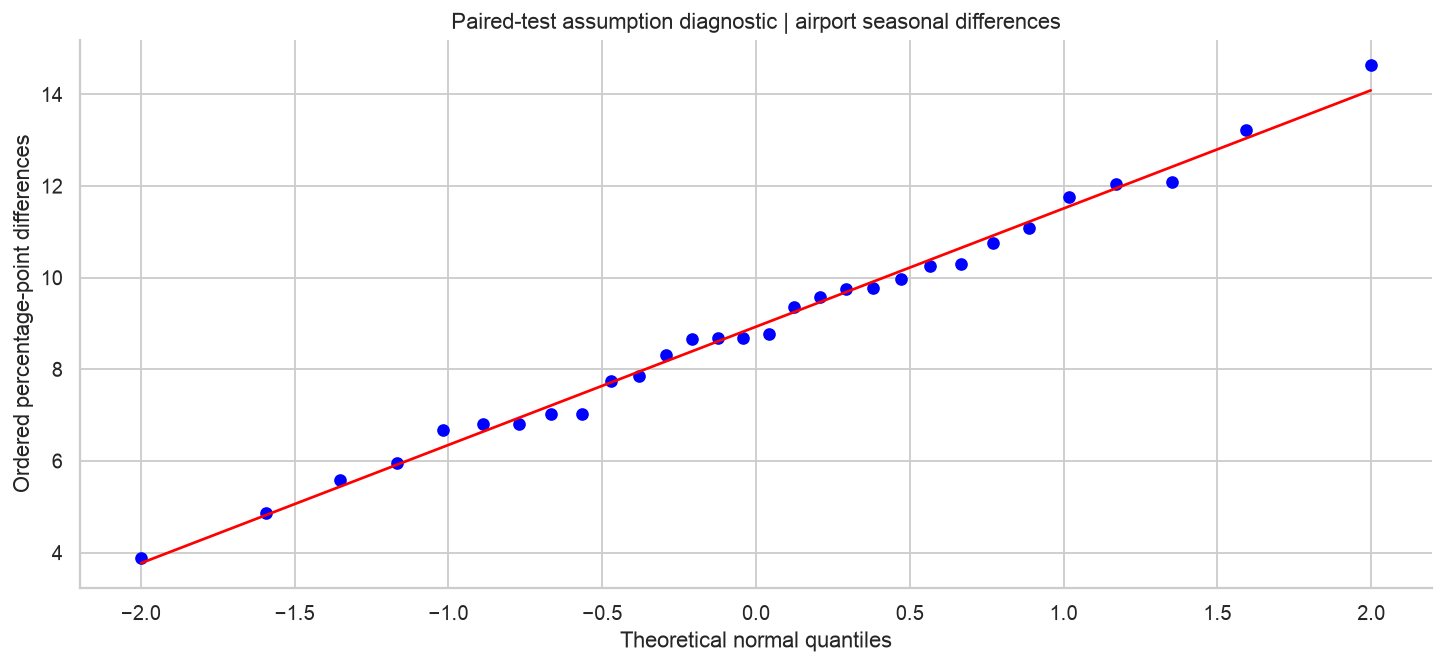

**Reject H₀.** Summer minus autumn = **8.93 pp**, 95% CI [8.00, 9.86], p = 2.76e-18. This is an airport-average historical association, not a causal effect.

In [9]:
test, difference = seasonal_test(df)
display(pd.Series(test).to_frame('paired seasonal test'))
charts(df, tables, difference=difference)
display(Image(filename=str(ROOT / 'reports/figures/07_paired_seasons.png')))
display(Image(filename=str(ROOT / 'reports/figures/11_assumptions_qq.png')))
decision = 'Reject H₀' if test['p_value'] < test['alpha'] else 'Fail to reject H₀'
display(Markdown(f"**{decision}.** Summer minus autumn = **{test['difference_pp']:.2f} pp**, "
                 f"95% CI [{test['ci_low_pp']:.2f}, {test['ci_high_pp']:.2f}], p = {test['p_value']:.3g}. "
                 'This is an airport-average historical association, not a causal effect.'))

A percentage point is an absolute difference between percentages: 22% − 18% = 4 pp. Cohen dz divides the mean paired difference by the standard deviation of those differences. The confidence interval depends on assumptions and is not a guarantee for every airport.

No test is selected after inspecting significance. The sign-flip result is a sensitivity check, not a cure for dependence; symmetry and independent sign flips remain assumptions. Only one primary comparison is used, so no family of multiple primary tests is created.

**Core course checkpoint:** Phases 1–6 complete the workflow through hypothesis testing. The next phases address the full assignment's modelling and forecasting requirements.

## Phase 7 — Leakage-aware predictive modelling

At the start of target month t, predict the **carrier-airport-month late-arrival share**. Aggregate data cannot support individual flight classification or satisfaction prediction.

Only calendar sine/cosine features and **exact t-3/t-12** historical delay shares, t-3 cancellation share, t-3 delay burden and t-3 log flight volume enter the model. BTS normally releases monthly records after month end; a three-month information gap is deliberately conservative. Exact joins prevent a missing month from turning a row shift into a false calendar lag. Actual publication vintages/revisions are unavailable, so this remains a retrospective availability approximation.

Training: through September 2023; candidate selection: January–September 2024; refit: through September 2024; final test: 2025. All training and selection labels precede the test origin with a conservative publication gap. Two predeclared gradient-boosting configurations are compared on validation flight-weighted MAE. The baseline repeats the same segment's rate 12 months earlier. Never assume complexity wins.

Report MAE and RMSE in percentage points plus R². Both flight-weighted and equal-row errors are shown. Current-month flight volume is allowed for retrospective error weighting only; it is never a predictor. Training weights use historical volume. Cold-start segments lacking exact lag histories are excluded and coverage is reported.

In [10]:
features = build_features(df)
display(features[['date', 'carrier', 'airport', 'delay_rate', 'lag3_delay_rate', 'lag12_delay_rate']].tail())
prediction_metrics, predictions, prediction_design = prediction_analysis(df)
display(pd.Series(prediction_design).to_frame('prediction design'))
display(pd.read_csv(ROOT / 'reports/prediction_validation.csv'))
display(prediction_metrics)
display(pd.read_csv(ROOT / 'reports/prediction_importance.csv').sort_values('increase_mae_pp', ascending=False))

,date,carrier,airport,delay_rate,lag3_delay_rate,lag12_delay_rate
186044,2025-12-01,YX,TPA,0.000000,0.250000,0.285714
186045,2025-12-01,YX,TUL,0.283951,0.166667,0.216667
186046,2025-12-01,YX,TVC,0.375000,0.057143,0.220588
186047,2025-12-01,YX,TYS,0.363636,0.052632,0.276190
186048,2025-12-01,YX,XNA,0.500000,0.108434,0.205882


,prediction design
train_rows,92046
validation_rows,14981
test_rows,20149
test_all_clean_rows,22681
test_row_coverage_pct,88.836471
test_flight_coverage_pct,98.758758
features,"[month_sin, month_cos, lag3_delay_rate, lag12_..."
chosen_max_leaf_nodes,7
target,Carrier-airport-month late-arrival share; not ...
training_cutoff,2023-09; validation January–September 2024; re...


,max_leaf_nodes,mae_pp,rmse_pp,r2
0,7,5.818850,7.884658,0.049142
1,15,6.033697,8.208343,-0.030531


,model,weighting,mae_pp,rmse_pp,r2
0,Seasonal lag-12 baseline,target-month flight volume (evaluation only),5.975926,7.913172,-0.170673
1,Seasonal lag-12 baseline,equal carrier-airport-month weight,8.757672,12.230933,-0.357706
2,Gradient boosting candidate,target-month flight volume (evaluation only),4.585187,6.153907,0.291995
3,Gradient boosting candidate,equal carrier-airport-month weight,6.935313,9.808230,0.126893


,feature,increase_mae_pp
2,lag3_delay_rate,1.681849
1,month_cos,0.611696
3,lag12_delay_rate,0.350699
0,month_sin,0.320885
4,lag3_cancel_rate,0.073407
5,lag3_delay_burden,0.010364
6,lag3_log_volume,-0.024326


The 2025 test is a rolling historical-feature exercise: earlier 2025 outcomes may become t-3 information for later 2025 months, but no 2025 labels are used for fitting. The national forecast below uses a different, fixed-origin design. Feature permutation importance is a held-out diagnostic, not a causal driver estimate; correlated lag features can share importance. There are no individual binary classes here, so class imbalance is replaced by outcome-distribution, segment-volume and panel-coverage concerns.

## Phase 8 — Time-series forecasting

Forecast the national reported-scope **monthly late-arrival share**, a defensible rate supporting planning. There are 96 monthly timestamps, but only one final held-out year; uncertainty is substantial.

At 1 January 2025, assume only data through September 2024 are available. Forecast October 2024–December 2025 (15 steps), then evaluate January–December 2025. Compare a seasonal-naive baseline with additive seasonal exponential smoothing (ETS). Choose no-trend versus damped-trend ETS using a corresponding 2023 validation exercise trained only through September 2022. Both models respect the same publication gap.

The displayed band uses the 90th percentile of 12 absolute validation errors. It is illustrative and empirically checked on the test year; it is not a guaranteed 90% interval. COVID shocks, changing reporting mix and dependent errors limit extrapolation.

,forecast design
target,National reported-scope monthly late-arrival s...
validation,Forecast 2023 from observations through Septem...
final_test,Forecast 2025 from observations through Septem...
information_cutoff,Conservative three-month publication gap; fixe...
chosen_ets_trend,add
band,Symmetric 90th percentile absolute validation-...
band_radius_pp,5.669458
test_band_coverage_pct,100.0
limitations,Only 12 validation and 12 test months; depende...


,trend,mae_pp,rmse_pp,r2
0,none,3.432713,3.864747,0.133689
1,add,3.427845,3.864201,0.133934


,model,mae_pp,rmse_pp,r2
0,Seasonal naive,3.449078,4.539909,-0.556217
1,ETS candidate,2.073682,2.601223,0.489106


,actual,seasonal_naive,ets,ets_lower,ets_upper
date,,,,,
2025-01-01,0.182976,0.231060,0.198400,0.141706,0.255095
2025-02-01,0.205003,0.155745,0.199925,0.143231,0.256620
2025-03-01,0.191972,0.202371,0.189122,0.132427,0.245816
2025-04-01,0.193684,0.186843,0.181747,0.125052,0.238441
2025-05-01,0.232572,0.256375,0.195442,0.138748,0.252137
2025-06-01,0.277027,0.241492,0.236392,0.179698,0.293087
2025-07-01,0.277118,0.283310,0.243624,0.186930,0.300319
2025-08-01,0.218415,0.227068,0.220467,0.163772,0.277161
2025-09-01,0.161469,0.153000,0.166000,0.109305,0.222694


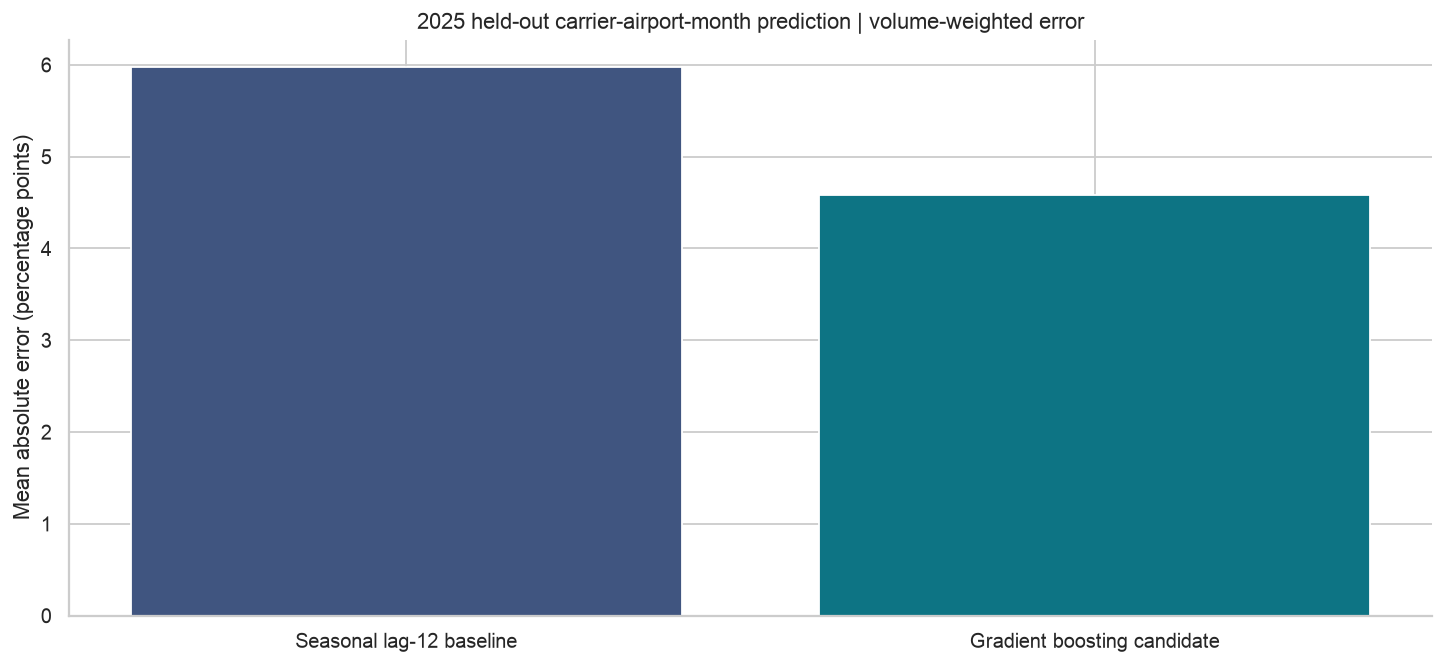

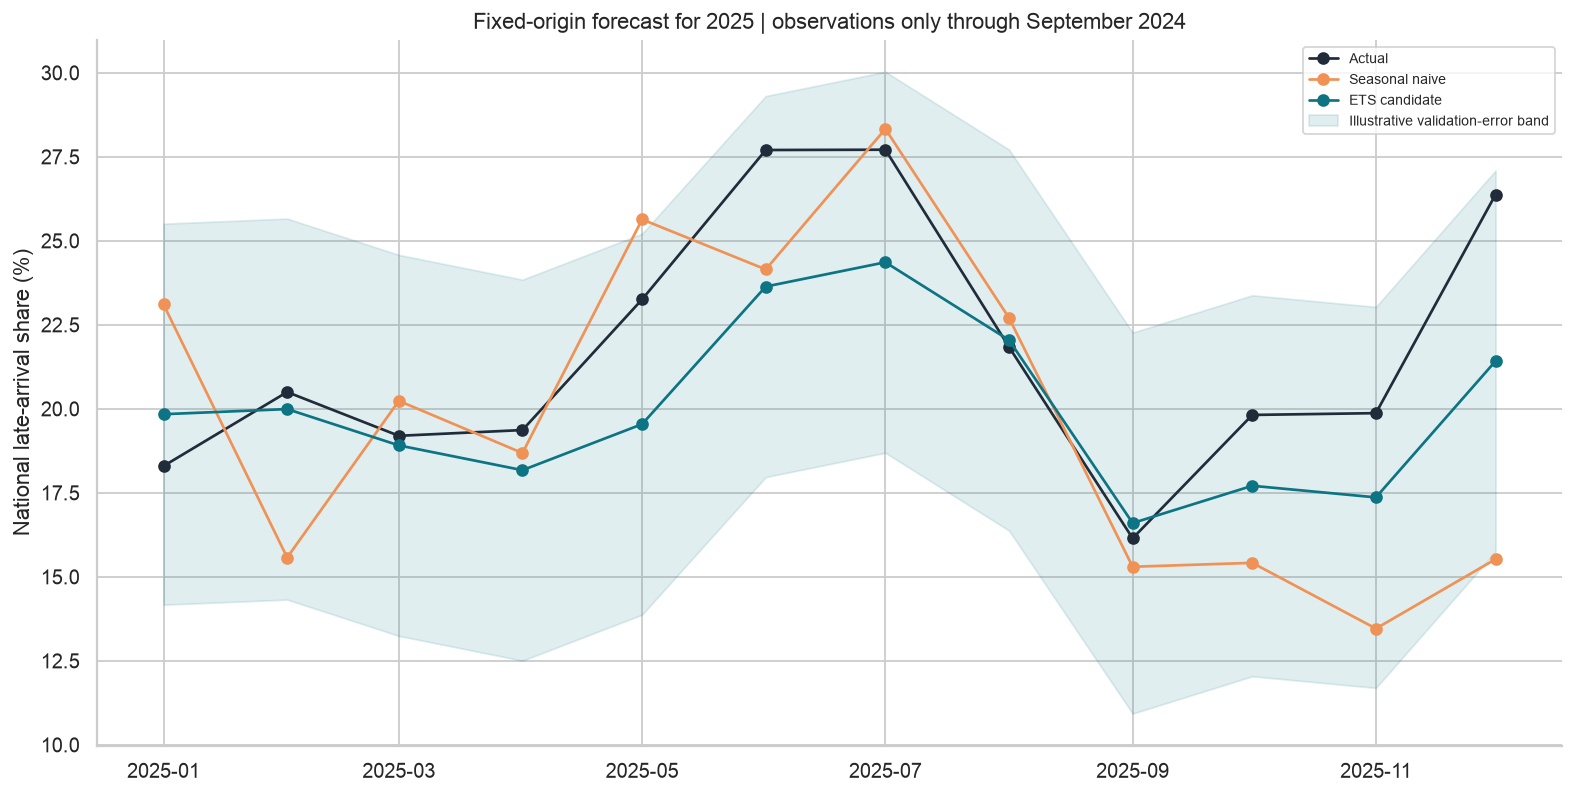

In [11]:
forecast_metrics, forecast_output, forecast_design = forecasting(tables['monthly'])
display(pd.Series(forecast_design).to_frame('forecast design'))
display(pd.read_csv(ROOT / 'reports/forecast_validation.csv'))
display(forecast_metrics)
display(forecast_output)
charts(df, tables, difference, prediction_metrics, predictions, forecast_output)
display(Image(filename=str(ROOT / 'reports/figures/08_prediction_comparison.png')))
display(Image(filename=str(ROOT / 'reports/figures/09_forecast.png')))

## Phase 9 — Business interpretation and decision analysis

Use validated evidence to propose investigation priorities, not unsupported causal promises. Prioritize a high delayed-flight count alongside its rate and volume, investigate the attribution mix, and test feasible interventions in a monitored pilot. Review the candidate model honestly against the baseline.

SQL is applicable to this tabular fact table. The next cell runs the supplied SQLite-compatible queries and reconciles their totals with Pandas. The priority table uses **2025** records and a 10,000-flight threshold. It is distinct from the all-period descriptive rankings.

In [12]:
sql_analysis(df)
print((ROOT / 'sql/analysis.sql').read_text())
display(pd.read_csv(ROOT / 'reports/sql_result_3.csv'))
write_reports(audit, metrics, test, tables, prediction_metrics, prediction_design,
              forecast_metrics, forecast_design)
display(Markdown((ROOT / 'reports/findings.md').read_text()))

-- Grain: one month x carrier x arrival airport. Never average row rates.
SELECT year, month, SUM(arr_flights) AS reported_flights,
       100.0 * SUM(arr_del15) / NULLIF(SUM(arr_flights), 0) AS late_arrival_pct,
       100.0 * SUM(arr_cancelled) / NULLIF(SUM(arr_flights), 0) AS cancellation_pct
FROM delays GROUP BY year, month ORDER BY year, month;

SELECT carrier, SUM(arr_flights) AS reported_flights,
       100.0 * SUM(arr_del15) / NULLIF(SUM(arr_flights), 0) AS late_arrival_pct
FROM delays GROUP BY carrier HAVING SUM(arr_flights) >= 10000
ORDER BY late_arrival_pct DESC;

SELECT carrier, airport, SUM(arr_flights) AS reported_flights,
       SUM(arr_del15) AS delayed_arrivals,
       100.0 * SUM(arr_del15) / NULLIF(SUM(arr_flights), 0) AS late_arrival_pct
FROM delays WHERE year = 2025
GROUP BY carrier, airport HAVING SUM(arr_flights) >= 10000
ORDER BY delayed_arrivals DESC LIMIT 20;



,carrier,airport,reported_flights,delayed_arrivals,late_arrival_pct
0,AA,DFW,163786.0,40756.0,24.883690
1,DL,ATL,237195.0,38265.0,16.132296
2,WN,DEN,90445.0,22451.0,24.822820
3,AA,CLT,117913.0,21679.0,18.385589
4,UA,DEN,105682.0,21599.0,20.437728
5,UA,ORD,95560.0,21360.0,22.352449
6,OO,ORD,66576.0,19329.0,29.032985
7,AS,SEA,75636.0,17905.0,23.672590
8,UA,EWR,66742.0,17266.0,25.869767
9,OO,DEN,74733.0,17196.0,23.009915


# Airline operations: executive findings

## Scope and decision

Use official BTS monthly operational aggregates to prioritize delay investigations. Historical coverage: **January 2018–December 2025**; **186,049 usable carrier-airport-month records**. Figures describe the downloaded US domestic reporting scope, not all aviation worldwide. Passenger satisfaction, route origins and individual aircraft are absent and are not inferred.

## Performance snapshot

| Metric | Calculated value | Denominator / unit |
| --- | --- | --- |
| Reported flights | 56,850,634 | Sum of arr_flights |
| Late-arrival share | 18.74% | arr_del15 / reported flights |
| Cancellation share | 2.12% | cancelled / reported flights |
| Diversion share | 0.24% | diverted / reported flights |
| Minutes per delayed arrival | 69.31 | total recorded delay minutes / delayed arrivals |

Rates are ratios of summed counts. Missing operational records are excluded with a documented audit; the observed totals do not quantify their unknown flight volume.

## Statistical evidence: summer versus autumn

Compare June–August with September–November during **2023–2025** at the **30 largest airports selected using 2018–2022 volume**. Aggregate flights within each airport-season, then give each airport equal weight. The result addresses the typical selected airport, not the typical flight.

Null: the mean paired airport difference is zero. Alternative: a difference in either direction. Method: paired t-test; alpha = 0.05. The observed summer-minus-autumn difference is **8.93 percentage points**, 95% CI **[8.00, 9.86]**, **p = 2.76e-18**, paired Cohen dz = **3.58**. Reject the zero-difference null at alpha 0.05. **30 of 30** airports have a positive difference.

The project uses 2 percentage points as an explicit practical planning threshold; the measured mean difference is above this threshold. It is a study rule, not an established industry standard. Shapiro-Wilk p for paired differences = 0.999; review the Q-Q plot rather than treating this as proof of normality. Sign-flip sensitivity p = 5e-05 (20,000 seeded resamples; symmetry/independence assumptions still apply).

Airports share network and weather shocks. The top-airport sample is purposive, not a random national sample. The test is exploratory and does not establish that season itself causes delay or that the same difference will recur.

## Prediction: honest later-year comparison

Target: a **monthly carrier-airport late-arrival share**, predicted at the start of the month. This is aggregate regression, not individual flight classification. Train through September 2023, select the candidate configuration on January–September 2024, refit through September 2024, then evaluate on 2025. All fitting/selection labels are available before the January 2025 test origin under the conservative publication-gap assumption. Features contain exact t-3 and t-12 historical quantities and known calendar seasonality; current-month operational fields never enter the model. Test features update on a rolling basis with three-month-old information, while model coefficients remain fixed.

| 2025 model | Flight-weighted MAE (pp) | Flight-weighted RMSE (pp) |
| --- | --- | --- |
| Seasonal lag-12 baseline | 5.976 | 7.913 |
| Gradient boosting candidate | 4.585 | 6.154 |

The lower flight-weighted MAE belongs to the **gradient boosting candidate**. Candidate relative MAE change versus baseline: **23.3% reduction** (negative means deterioration). Report equal-row metrics alongside volume-weighted metrics in `prediction_metrics.csv` so large airports do not hide small-segment errors. Coverage: **20,149 test records**, **88.8% of 2025 clean rows** and **98.8% of 2025 clean flight volume**. Segments without the required history are excluded; cold-start performance is unknown.

Current-month flight volume is used only to evaluate exposure-weighted error after outcomes are observed. Training weights use lagged volume. Publication-vintage data are unavailable; using a conservative three-month gap reduces leakage risk but cannot reconstruct every historical revision or publication delay. Do not deploy without vintage-based validation and drift checks.

## Forecasting: monthly national late-arrival share

Choose ETS trend specification on the 2023 validation year using data only through September 2022, so all selection labels are available before the January 2025 test origin. For the fixed-origin 2025 evaluation, use data only through September 2024, forecast 15 months and score the final 12. The seasonal naive baseline recursively repeats the latest available same-calendar-month rate; it respects the same availability gap.

| 2025 forecast | MAE (pp) | RMSE (pp) |
| --- | --- | --- |
| Seasonal naive | 3.449 | 4.540 |
| ETS candidate | 2.074 | 2.601 |

The lower test RMSE belongs to the **ETS candidate**. The displayed ETS band is ±**5.67 pp**, based on the 90th percentile of absolute 2023 validation errors. It covers **100.0%** of 2025 months. It is an illustrative planning band, not a guaranteed 90% prediction interval: there are only 12 dependent validation errors. COVID-era structural breaks and limited holdout years constrain generalization.

## Priorities, actions and trade-offs

1. **Prioritize exposure, then diagnose.** Review the carrier-airport segments in `sql_result_3.csv` ranked by 2025 delayed-arrival counts with at least 10,000 reported flights. High rates at tiny airports and high counts at large hubs answer different questions. Use both rate and volume before allocating investigation time.
2. **Plan a seasonal review.** Use the observed seasonal difference to schedule a pre-summer operations review. Confirm capacity, schedules and local causes with managers before changing resources. The paired comparison is a planning signal, not an estimated treatment benefit.
3. **Investigate attributed causes.** The cause-minute chart distinguishes carrier, NAS, late-aircraft, weather and security exposure. NAS includes some non-extreme weather; the weather category is not all weather. Protect the small unallocated source gap. Prioritize feasible causes and do not assume all attributed minutes are avoidable.
4. **Prefer the validated winner.** Keep the simple baseline whenever the candidate loses. Evaluate additional years and error by segment before using either model operationally. Predictions should support a review queue, not automatic penalties or passenger eligibility decisions.
5. **Measure a pilot.** A hypothetical 1-percentage-point reduction over 100,000 comparable reported flights would correspond to 1,000 fewer late arrivals. This is arithmetic scenario analysis, not a forecast of achievable benefit. Actual financial return, staffing and passenger impact cannot be estimated from these fields.

Monitor monthly late share, cancellation share, flight volume, missingness, source reconciliation gaps, and model errors. Review comparable seasons and segment mix; use a controlled or carefully matched pilot to estimate any intervention effect.

## Assumptions and responsible use

The source's reported categories are used as defined by BTS; no flight-level deduplication is possible from monthly aggregates. Missingness and name changes are documented. Outliers and pandemic months are retained. Operational counts contain no direct passenger identifiers. Public carrier/airport comparisons can still be misleading without context; they are associations affected by network mix. There is no individual fairness claim because no passenger attributes are available. Geographic and volume disparities in error should be monitored separately.

This project was prepared with AI assistance. The student should rerun it, explain the methods and limitations, and follow course attribution rules. No personal name, institution, survey result or satisfaction score has been invented.

## Sources

- [BTS Airline On-Time Statistics and Delay Causes](https://www.transtats.bts.gov/OT_Delay/OT_DelayCause1.asp), official download and reporting-scope notes.
- [BTS definitions and reporting coverage](https://www.bts.gov/explore-topics-and-geography/topics/airline-time-performance-and-causes-flight-delays), including the 15-minute late-arrival threshold and cause definitions.
- Exact download URL, server archive filename, download date, raw byte sizes and hashes: `data/raw/provenance.json`.


## Phase 10 — Presentation and reproducibility

The generated executive HTML report embeds every chart and the audit, so it can be opened without Python. A separate dashboard specification defines data grain, filters, measures and guardrails for Power BI/Tableau. The submission includes original and cleaned data handling, dictionary, SQL, KPI tables, model/forecast outputs, assumptions, responsible-use notes, and automated checks.

Reproduce with `python -m src.analysis`, then `python -m unittest discover -s tests -v`. Execute and export this notebook with `python scripts/execute_notebook.py`. All statistical random resampling and model seeds are fixed at 42. No GitHub login is needed locally.

In [13]:
import unittest
suite = unittest.defaultTestLoader.discover(str(ROOT / 'tests'))
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful(), 'Resolve failed validation before submission.'
print('Generated chart count:', len(list((ROOT / 'reports/figures').glob('*.png'))))
print('All analyses completed. Open reports/executive_report.html for the presentation report.')

test_calendar_lag_with_missing_months (test_analysis.AnalyticsTests.test_calendar_lag_with_missing_months) ... 

ok


test_forecast_baseline_recurses_without_future_actuals (test_analysis.AnalyticsTests.test_forecast_baseline_recurses_without_future_actuals) ... 

ok


test_generated_results_reconcile (test_analysis.AnalyticsTests.test_generated_results_reconcile) ... 

ok

... (2 outputs left out)

test_unchanged_source_and_business_keys (test_analysis.AnalyticsTests.test_unchanged_source_and_business_keys) ... 

ok


----------------------------------------------------------------------
Ran 5 tests in 0.414s

OK


Generated chart count: 11
All analyses completed. Open reports/executive_report.html for the presentation report.


## What to explain in a viva

1. **Grain:** monthly carrier × arrival-airport summaries, not individual flights or customers.
2. **Cleaning:** structural zero evidence, excluded missing operational rows, retained outliers and source gaps.
3. **KPI:** a ratio of sums with an explicit denominator; a 15-minute arrival threshold.
4. **Inference:** paired airport differences, p-value, confidence interval, effect size, assumptions and practical threshold.
5. **Prediction:** exact historical features, publication lag, chronological train/validation/test, cold-start coverage and baseline comparison.
6. **Forecast:** fixed information cutoff, seasonal naive versus ETS, later-year error and uncertain bands.
7. **Action:** prioritize investigation, confirm causes locally, monitor a pilot, and avoid causal or satisfaction claims.

Read `docs/EXPLANATION_GUIDE.md` for a detailed plain-language walkthrough and answers to likely questions.